In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1; np.random.seed(0)

In [ ]:
# import custom 3CA dataloader
pth_3ca = os.path.join('..','..','..','..','..','..','cancer','vertebrate','CCCA')
sys.path.append(os.path.join(pth_3ca,'scripts'))
from load import load_CCCA_adata

In [ ]:
# paths  (this dataset dir carries a '-2' testing suffix; input folder has no suffix)
name    = 'Chen2020_Head-and-Neck-2'      # output subdir
dataset = 'Chen2020_Head-and-Neck'        # input data folder (minus 'Data_')
cat     = 'Head-and-Neck'
pth      = os.path.join('..','..','..','..','..','..')
pth_data = os.path.join(pth,'data')
pth_in   = os.path.join(pth_data,'unzip','CCCA', f'Data_{dataset}')
pth_out  = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_fig  = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True)

In [ ]:
# load dataset -> select malignant cells
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant cells:', adata.n_obs, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Chen2020_Head-and-Neck
Done.
malignant cells: 3763 | samples: 14


sample
P09       4
P15       5
P10       6
P07      13
P08      25
P02      36
P03     107
P04     112
P05     136
P14     197
P06     234
P12     236
P01     838
P11    1814

chosen threshold: keep sample >= 107 cells  (largest interior gap, ratio 2.97)


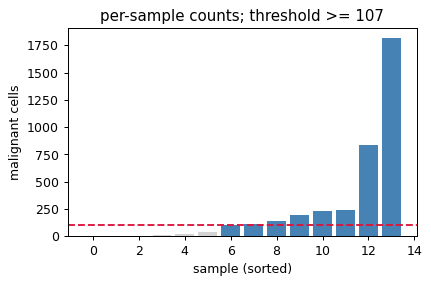

In [ ]:
# inspect per-sample cell counts -> gap-finding threshold (derived, not inherited)
n = adata.obs['sample'].value_counts().sort_values()
v = n.values
# largest interior ratio-gap that leaves >=4 samples (enough for Harmony on 'sample')
ratios = [(v[i+1]/v[i], v[i+1]) for i in range(len(v)-1) if (v>=v[i+1]).sum() >= 4]
gap_ratio, thr = max(ratios)
print(n.to_string())
print(f'\nchosen threshold: keep sample >= {thr} cells  (largest interior gap, ratio {gap_ratio:.2f})')
fig,ax = plt.subplots(figsize=(5,3))
ax.bar(range(len(v)), v, color=['lightgray' if x<thr else 'steelblue' for x in v])
ax.axhline(thr, ls='--', c='crimson'); ax.set_ylabel('malignant cells'); ax.set_xlabel('sample (sorted)')
ax.set_title(f'per-sample counts; threshold >= {thr}'); plt.show()

In [ ]:
# apply threshold
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'after threshold: {adata.n_obs} cells, {adata.obs["sample"].nunique()} samples')
print('kept:', sorted(keep.tolist()))

after threshold: 3674 cells, 8 samples
kept: ['P01', 'P03', 'P04', 'P05', 'P06', 'P11', 'P12', 'P14']


In [ ]:
# filter genes + select over-dispersed features (scFates GAM)
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('genes:', adata.n_vars, '| over-dispersed:', int(adata.var.highly_variable.sum()))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1290 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

genes: 22080 | over-dispersed: 1290


n_pcs (>0.5% variance each): 19


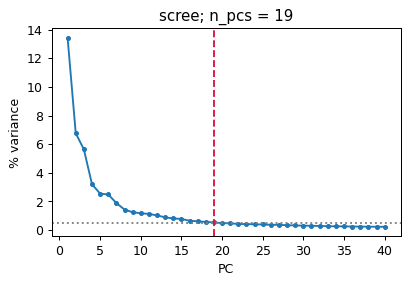

In [ ]:
# PCA -> choose n_pcs from the variance ratio (derived; bounded to the 10x scale).
# NOTE: PCA runs on log1p over-dispersed genes with NO sc.pp.scale() z-scoring, matching the
# Puram reference protocol. Z-scoring to unit variance up-weights low-count patient-private/CNV
# genes and inflates patient separation; adding it reproduces the prior attempts' apparent Gate-1
# NO-GO (diff-sample-neighbour frac 0.26 / 32% patient-pure vs 0.47 / 4% without scaling).
sc.pp.pca(adata, n_comps=50, use_highly_variable=True)
vr = adata.uns['pca']['variance_ratio']
n_pcs = int((vr > 0.005).sum())   # PCs each explaining >0.5% variance
print('n_pcs (>0.5% variance each):', n_pcs)
fig,ax = plt.subplots(figsize=(5,3))
ax.plot(np.arange(1,41), vr[:40]*100, 'o-', ms=3); ax.axvline(n_pcs, ls='--', c='crimson')
ax.axhline(0.5, ls=':', c='gray'); ax.set_xlabel('PC'); ax.set_ylabel('% variance')
ax.set_title(f'scree; n_pcs = {n_pcs}'); plt.show()

theta= 0: iLISI=1.03/3.23  diff-frac=0.014/0.690
theta= 1: iLISI=1.24/3.23  diff-frac=0.121/0.690
theta= 2: iLISI=2.13/3.23  diff-frac=0.476/0.690
theta= 5: iLISI=2.17/3.23  diff-frac=0.482/0.690
theta=10: iLISI=2.14/3.23  diff-frac=0.473/0.690


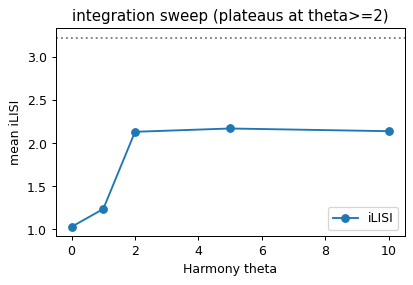

In [ ]:
# --- Gate 1 evidence: integration-strength sweep with a per-neighborhood metric (iLISI) ---
# never gate on a scalar; sweep theta through the 10x precedent (Kurten reached theta=10)
codes = pd.Categorical(adata.obs['sample'].astype(str)).codes
p = pd.Series(codes).value_counts(normalize=True).values
ceil_ilisi = 1/np.sum(p**2); ceil_diff = 1-np.sum(p**2)
def ilisi(rep, codes, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = codes[idx]; ns = codes.max()+1
    il = np.array([1/np.sum((np.bincount(r,minlength=ns)/k)**2) for r in lab])
    df = (lab != codes[:,None]).mean(1)
    return il.mean(), df.mean()
rows=[]
for th in [0,1,2,5,10]:
    ad = adata.copy()
    if th==0: rep = ad.obsm['X_pca'][:,:n_pcs]
    else:
        sce.pp.harmony_integrate(ad, 'sample', theta=th, max_iter_harmony=20)
        rep = ad.obsm['X_pca_harmony'][:,:n_pcs]
    im, dm = ilisi(rep, codes)
    rows.append((th, im, dm)); print(f'theta={th:2d}: iLISI={im:.2f}/{ceil_ilisi:.2f}  diff-frac={dm:.3f}/{ceil_diff:.3f}')
sw = pd.DataFrame(rows, columns=['theta','iLISI','diff']).set_index('theta')
fig,ax = plt.subplots(figsize=(5,3))
ax.plot(sw.index, sw.iLISI, 'o-', label='iLISI'); ax.axhline(ceil_ilisi, ls=':', c='gray')
ax.set_xlabel('Harmony theta'); ax.set_ylabel('mean iLISI'); ax.set_title('integration sweep (plateaus at theta>=2)')
ax.legend(); plt.show()
# metrics plateau at theta>=2 -> theta=2 is stable integration, not under-integration (over-integration null check)

In [ ]:
# integrate samples at chosen strength
theta = 2
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20)

In [ ]:
# neighbors -> UMAP  (do NOT re-embed later: continuity read off an independent graph)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=15)
sc.tl.umap(adata, spread=1.0, min_dist=0.5, random_state=0)

In [ ]:
# island check: connected components of the kNN graph (keep the largest; here it is already one)
ncomp, lab = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN-graph connected components:', ncomp)
if ncomp > 1:
    from collections import Counter; keep_lab = Counter(lab).most_common(1)[0][0]
    adata = adata[lab==keep_lab].copy(); print('kept largest component:', adata.n_obs)
else:
    print('single connected component -> no detached islands to remove; keep all', adata.n_obs)

kNN-graph connected components: 1
single connected component -> no detached islands to remove; keep all 3674


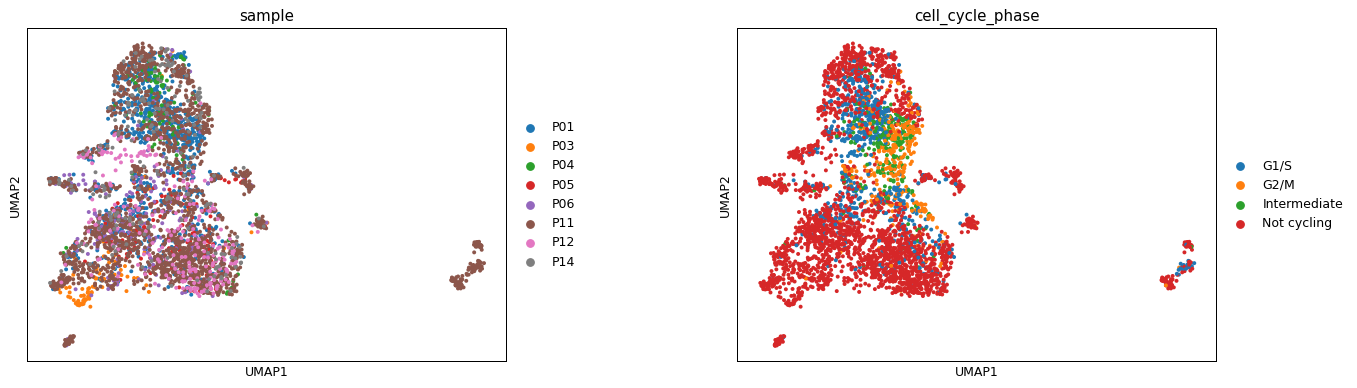

In [ ]:
# Gate-1 read: embedding colored by sample / cell cycle (mixed + continuous?)
sc.pl.umap(adata, color=['sample','cell_cycle_phase'], size=40, wspace=.35)

In [ ]:
# annotate cell states: cluster (Leiden), label each cluster by dominant 3CA meta-program collapsed
# into coarse families, then apply de-novo-marker overrides where markers are unambiguous lineage
# signals (protocol: annotation uses BOTH data-derived markers AND reported programs, never one alone).
# Note: ribosomal (RPL/RPS) genes are NOT used as an override -- they are ubiquitously high in
# proliferating cells and would mislabel the cycling body.
sc.tl.leiden(adata, resolution=0.3, flavor='igraph', n_iterations=2, directed=False, random_state=0)
sc.tl.rank_genes_groups(adata, 'leiden', method='wilcoxon', n_genes=15)
def collapse(mp):
    mp=str(mp)
    if mp.startswith('Cell Cycle') or mp.startswith('MYC'): return 'Cycling'
    if mp.startswith('EMT'):        return 'EMT'
    if mp.startswith('Interferon'): return 'IFN/MHC-II'
    for k,v in [('Hypoxia','Hypoxia'),('Respiration','Respiration'),('Stress','Stress'),
                ('EpiSen','Squamous/Basal'),('NPC','Progenitor-like'),
                ('Translation','Respiration'),('Protein maturation','Respiration')]:
        if mp.startswith(k): return v
    return 'Other'
cl2state={cl: sub['mp_top'].map(collapse).value_counts().index[0]
          for cl,sub in adata.obs.groupby('leiden', observed=True)}
# unambiguous de-novo-marker overrides: squamous keratins, mitochondrial-high
for cl in cl2state:
    mk=set(adata.uns['rank_genes_groups']['names'][cl][:12])
    if {'KRT5','S100A2','SFN','KRT14','KRT17'} & mk:      cl2state[cl]='Squamous/Basal'
    elif sum(g.startswith('MT-') for g in mk) >= 4:       cl2state[cl]='Mitochondrial'
adata.obs['state']=adata.obs['leiden'].map(cl2state).astype('category')
adata.obs['celltype']=adata.obs['state']
print(adata.obs['state'].value_counts().to_string())
print('\nde-novo markers per cluster (corroboration):')
for cl in adata.obs['leiden'].cat.categories:
    print(f'  cl{cl} [{cl2state[cl]}]:', ', '.join(adata.uns['rank_genes_groups']['names'][cl][:8]))

state
Cycling           1335
Mitochondrial      870
Squamous/Basal     830
Hypoxia            300
Respiration        263
IFN/MHC-II          41
Other               35

de-novo markers per cluster (corroboration):
  cl0 [Cycling]: NPM1, RAN, RPL17, YBX1, RPL23A, NME2, RPL5, H2AFZ
  cl1 [Squamous/Basal]: S100A11, KRT5, S100A2, HSPB1, SFN, TXNDC17, PYCARD, FXYD3
  cl2 [Respiration]: RPS11, RPS24, RPL10A, RPL13A, EEF1A1, RPL37A, RPL4, RPL3
  cl3 [Mitochondrial]: MT-ND3, MT-ND4, MT-CO2, MT-CYB, MT-ND2, MT-ATP6, MT-CO3, MT-CO1
  cl4 [Respiration]: RACK1, EEF2, RPL10A, RPL13, MARCKSL1, RPS14, RPS4X, BTG2
  cl5 [Hypoxia]: SAT1, TMSB4X, TACSTD2, ANXA2, SLPI, S100A10, KRT6A, FTH1
  cl6 [IFN/MHC-II]: TMSB4X, MALAT1, B2M, EIF5A, C1orf56, CRIP1, ACTB, S100A4
  cl7 [Other]: RPL39, RPL7, RPL21, RPS13, RPL34, RPL26, SNHG29, C1orf56
  cl8 [Cycling]: CCL20, IGFBP2, SNHG29, PTMA, CSTA, RPL21, TPT1, FTH1


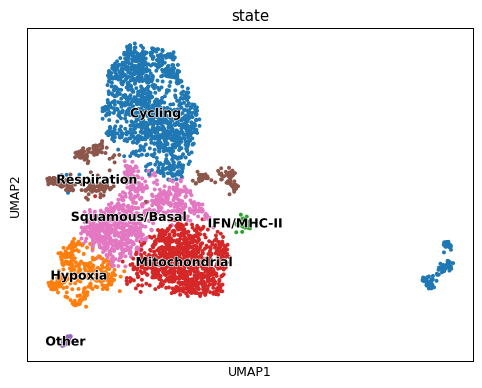

In [ ]:
# visual inspection — states on the manifold
sc.pl.umap(adata, color='state', size=40, legend_loc='on data', legend_fontoutline=1)

In [ ]:
# save processed data to h5ad file
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('wrote', os.path.join(pth_out, 'processed.h5ad'), adata.shape)

wrote ../../../../../../data/cancer/vertebrate/CCCA/Claude/Head-and-Neck/Chen2020_Head-and-Neck-2/processed.h5ad (3674, 22080)


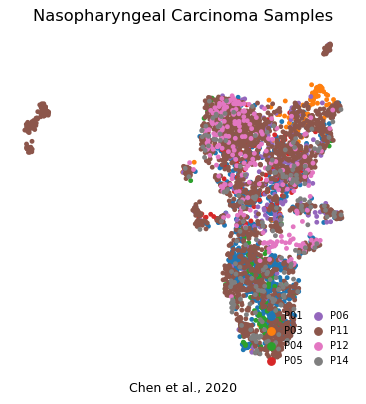

In [ ]:
# save sample-integration figure (samples.pdf) -- reference single-panel layout
fig, ax = plt.subplots(1, 1, figsize=(5,5))
sc.pl.umap(adata, color='sample', size=60, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='lower right', columnspacing=.5, handletextpad=.25, fontsize=8)
ax.set_title('Nasopharyngeal Carcinoma Samples', size=13)
ax.text(.5, -.05, 'Chen et al., 2020', ha='center', transform=ax.transAxes)
plt.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()